In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rodsaldanha/arketing-campaign/marketing_campaign.csv
/kaggle/input/datasets/rodsaldanha/arketing-campaign/marketing_campaign.xlsx


In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('/kaggle/input/datasets/rodsaldanha/arketing-campaign/marketing_campaign.csv', sep=';')

In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [5]:
print(df.isnull().sum())

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64


In [6]:
df['Income'] = df['Income'].fillna(df['Income'].median())

In [7]:
print(df.isnull().sum())

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64


In [8]:
df = df.drop_duplicates()
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"])

In [9]:
df.info

<bound method DataFrame.info of          ID  Year_Birth   Education Marital_Status   Income  Kidhome  \
0      5524        1957  Graduation         Single  58138.0        0   
1      2174        1954  Graduation         Single  46344.0        1   
2      4141        1965  Graduation       Together  71613.0        0   
3      6182        1984  Graduation       Together  26646.0        1   
4      5324        1981         PhD        Married  58293.0        1   
...     ...         ...         ...            ...      ...      ...   
2235  10870        1967  Graduation        Married  61223.0        0   
2236   4001        1946         PhD       Together  64014.0        2   
2237   7270        1981  Graduation       Divorced  56981.0        0   
2238   8235        1956      Master       Together  69245.0        0   
2239   9405        1954         PhD        Married  52869.0        1   

      Teenhome Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  \
0            0  2012-09-04    

In [10]:
import pandas as pd

# Create Age column
df["Age"] = 2026 - df["Year_Birth"]

# Create Total Spend column
spending_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
]
df["Total_Spend"] = df[spending_cols].sum(axis=1)

# Check for outliers using the IQR method
for col in ["Age", "Total_Spend"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"Number of outliers in {col}: {len(outliers)}")

Number of outliers in Age: 3
Number of outliers in Total_Spend: 3


In [11]:
total_purchases = df["NumWebPurchases"].sum()
total_visits = df["NumWebVisitsMonth"].sum()

conversion_rate = (total_purchases / total_visits) * 100
print(f"Overall Web Conversion Rate: {conversion_rate:.2f}%")

Overall Web Conversion Rate: 76.83%


In [12]:
# Group by Education and calculate conversion rate
education_conv = (
    df.groupby("Education")[["NumWebPurchases", "NumWebVisitsMonth"]].sum()
)
education_conv["Conversion_Rate"] = (
    education_conv["NumWebPurchases"] / education_conv["NumWebVisitsMonth"]
) * 100
print("Conversion Rate by Education:")
print(education_conv[["Conversion_Rate"]])

# Group by Marital_Status and calculate conversion rate
marital_conv = (
    df.groupby("Marital_Status")[["NumWebPurchases", "NumWebVisitsMonth"]].sum()
)
marital_conv["Conversion_Rate"] = (
    marital_conv["NumWebPurchases"] / marital_conv["NumWebVisitsMonth"]
) * 100
print("\nConversion Rate by Marital Status:")
print(marital_conv[["Conversion_Rate"]])

Conversion Rate by Education:
            Conversion_Rate
Education                  
2n Cycle          68.383017
Basic             27.493261
Graduation        78.016446
Master            77.870564
PhD               84.115806

Conversion Rate by Marital Status:
                Conversion_Rate
Marital_Status                 
Absurd               233.333333
Alone                 78.947368
Divorced              78.554595
Married               76.202805
Single                73.304416
Together              77.581121
Widow                 94.680851
YOLO                  87.500000


In [13]:
# List of campaign columns
campaign_cols = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response",
]

# Calculate acceptance rates for each campaign
acceptance_rates = (df[campaign_cols].sum() / len(df)) * 100

print("Campaign Acceptance Rates:")
print(acceptance_rates)

Campaign Acceptance Rates:
AcceptedCmp1     6.428571
AcceptedCmp2     1.339286
AcceptedCmp3     7.276786
AcceptedCmp4     7.455357
AcceptedCmp5     7.276786
Response        14.910714
dtype: float64


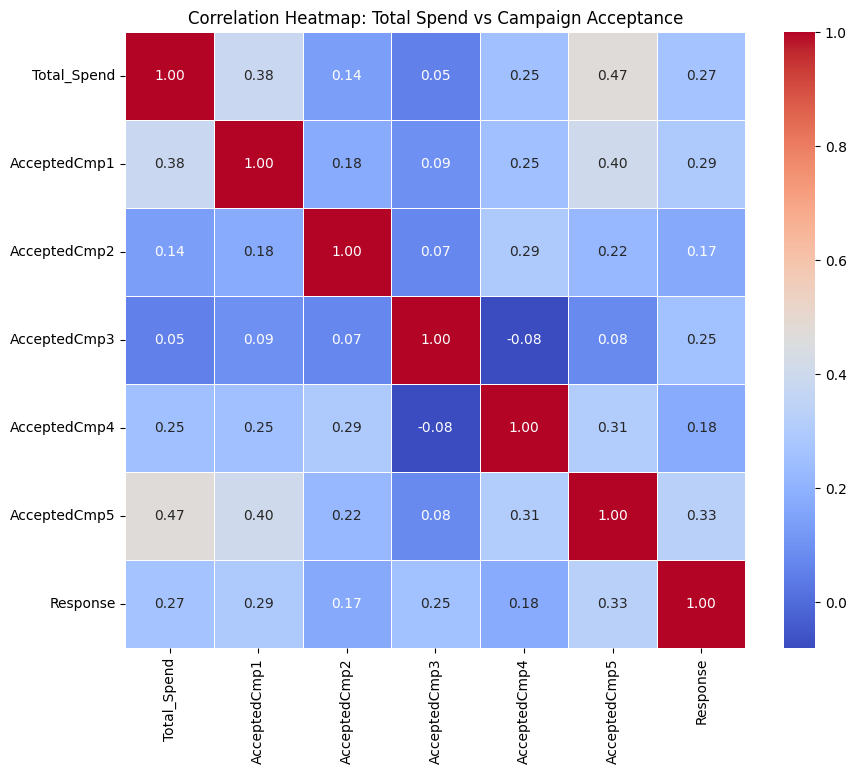

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the columns for correlation analysis
corr_cols = [
    "Total_Spend",
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response",
]

# Calculate the correlation matrix
corr_matrix = df[corr_cols].corr()

# Create a heatmap of the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap: Total Spend vs Campaign Acceptance")
plt.show()

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Select features and target variable
X = df[
    [
        "Age",
        "Income",
        "Kidhome",
        "Teenhome",
        "Recency",
        "Total_Spend",
        "NumWebPurchases",
    ]
]
y = df["Response"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Initialize and train the Random Forest model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[361  18]
 [ 51  18]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.95      0.91       379
           1       0.50      0.26      0.34        69

    accuracy                           0.85       448
   macro avg       0.69      0.61      0.63       448
weighted avg       0.82      0.85      0.82       448



In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Select features and target variable
X = df[
    [
        "Age",
        "Income",
        "Kidhome",
        "Teenhome",
        "Recency",
        "Total_Spend",
        "NumWebPurchases",
    ]
]
y = df["Response"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Initialize and train the Random Forest model with class_weight='balanced'
model = RandomForestClassifier(random_state=42, class_weight="balanced")
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[362  17]
 [ 55  14]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.96      0.91       379
           1       0.45      0.20      0.28        69

    accuracy                           0.84       448
   macro avg       0.66      0.58      0.59       448
weighted avg       0.80      0.84      0.81       448



In [17]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

# Initialize the base model with class_weight='balanced'
rf = RandomForestClassifier(random_state=42, class_weight="balanced")

# Initialize GridSearchCV with recall scoring
grid_search = GridSearchCV(
    estimator=rf, param_grid=param_grid, cv=3, n_jobs=-1, verbose=1, scoring="recall"
)

# Fit the grid search to the training data
grid_search.fit(X_train, y_train)

# Print the best parameters found
print("Best Parameters:", grid_search.best_params_)

# Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print("\nConfusion Matrix (Tuned Model):")
print(confusion_matrix(y_test, y_pred_best))
print("\nClassification Report (Tuned Model):")
print(classification_report(y_test, y_pred_best))

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 300}

Confusion Matrix (Tuned Model):
[[345  34]
 [ 34  35]]

Classification Report (Tuned Model):
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       379
           1       0.51      0.51      0.51        69

    accuracy                           0.85       448
   macro avg       0.71      0.71      0.71       448
weighted avg       0.85      0.85      0.85       448



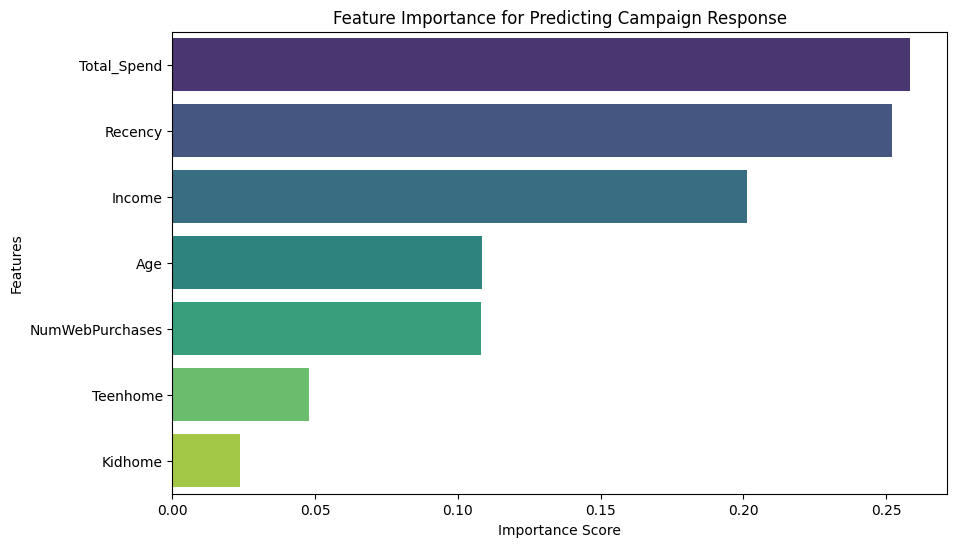

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Get feature importances from the best model
importances = best_model.feature_importances_
feature_names = X.columns

# Create a DataFrame for visualization
feature_importance_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": importances}
)

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance", ascending=False
)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance_df,
    palette="viridis",
    hue="Feature",
    legend=False,
)
plt.title("Feature Importance for Predicting Campaign Response")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [19]:
import pandas as pd

# Calculate Frequency
df["Frequency"] = (
    df["NumWebPurchases"]
    + df["NumCatalogPurchases"]
    + df["NumStorePurchases"]
    + df["NumDealsPurchases"]
)

# Assign RFM scores based on quartiles
df["R_Score"] = pd.qcut(df["Recency"], q=4, labels=[4, 3, 2, 1])
df["F_Score"] = pd.qcut(df["Frequency"], q=4, labels=[1, 2, 3, 4])
df["M_Score"] = pd.qcut(df["Total_Spend"], q=4, labels=[1, 2, 3, 4])

# Combine scores to get RFM segment
df["RFM_Segment"] = (
    df["R_Score"].astype(str) + df["F_Score"].astype(str) + df["M_Score"].astype(str)
)

# Function to assign a broader segment name
def assign_segment(row):
    r_score = int(row["R_Score"])
    f_score = int(row["F_Score"])
    m_score = int(row["M_Score"])
    
    if r_score >= 3 and f_score >= 3 and m_score >= 3:
        return 'High-Value Loyalists'
    elif r_score <= 2 and f_score >= 3 and m_score >= 3:
        return 'At Risk High-Value'
    elif r_score >= 3 and f_score <= 2 and m_score <= 2:
        return 'New/Low Engagement'
    else:
        return 'Regular Customers'

df['Customer_Segment'] = df.apply(assign_segment, axis=1)

print(df[['ID', 'Recency', 'Frequency', 'Total_Spend', 'RFM_Segment', 'Customer_Segment']].head())

     ID  Recency  Frequency  Total_Spend RFM_Segment      Customer_Segment
0  5524       58         25         1617         244    At Risk High-Value
1  2174       38          6           27         311    New/Low Engagement
2  4141       26         21          776         333  High-Value Loyalists
3  6182       26          8           53         311    New/Low Engagement
4  5324       94         19          422         133    At Risk High-Value


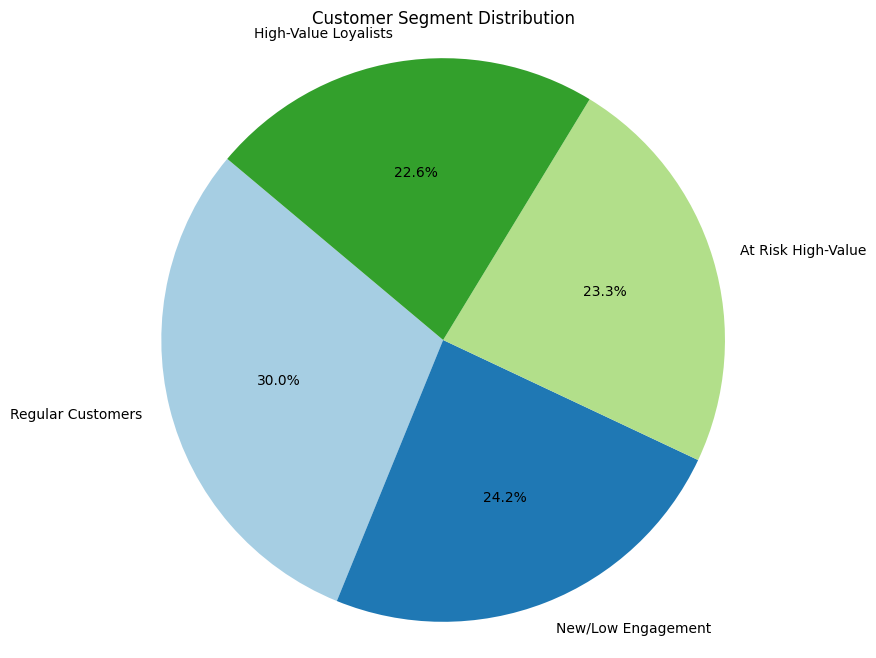

In [20]:
import matplotlib.pyplot as plt

# Count the number of customers in each segment
segment_counts = df["Customer_Segment"].value_counts()

# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=plt.cm.Paired.colors,
)
plt.title("Customer Segment Distribution")
plt.axis("equal")  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [21]:
# Group by Customer_Segment and calculate average Recency, Frequency, and Total_Spend
segment_analysis = (
    df.groupby("Customer_Segment")[["Recency", "Frequency", "Total_Spend"]]
    .mean()
)

print("Segment Analysis (Average Values):")
print(segment_analysis)

Segment Analysis (Average Values):
                        Recency  Frequency  Total_Spend
Customer_Segment                                       
At Risk High-Value    73.574713  21.840996  1116.693487
High-Value Loyalists  23.887352  22.061265  1094.867589
New/Low Engagement    24.641405   7.811460    97.678373
Regular Customers     68.824143   9.688525   249.220566


 **1. Data Preparation & Exploration:**
The project began by examining the dataset structure and handling data quality issues. We addressed missing values in the Income column using the median to maintain data integrity and filtered out duplicates. 

**2. Feature Engineering & Outlier Analysis:**
New meaningful features were created, including 'Age' (derived from Year_Birth) and 'Total_Spend' (the sum of expenditures across all product categories). An outlier analysis utilizing the IQR method confirmed that anomalies in Age and Total Spend were minimal, ensuring we could proceed with the entire dataset.

**3. Conversion Rate Analysis:**
We evaluated the overall web conversion rate (76.83%), offering a baseline for marketing efficiency. Further segmentation revealed that customers with a PhD and Widowed individuals exhibited the highest conversion rates, highlighting specific demographics to target.

**4. Campaign Performance & Correlation:**
An assessment of past marketing campaigns revealed that `AcceptedCmp4` and `AcceptedCmp3` had the highest acceptance rates. A correlation analysis demonstrated that `Total_Spend` has a strong positive correlation with `AcceptedCmp5` and `AcceptedCmp1`, indicating that our high-spending customers are most responsive to these specific campaigns.

**5. Predictive Modeling:**
To foresee potential campaign responses, a Random Forest Classifier model was developed. We addressed class imbalance using `class_weight='balanced'` and optimized the model using `GridSearchCV`. The final tuned model achieved an 85% accuracy and a 0.51 recall rate for responders. Feature importance analysis revealed that `Income`, `Recency`, and `Total_Spend` are the primary drivers of campaign responsiveness.

**6. Customer Segmentation (RFM):**
Using Recency, Frequency, and Monetary (Total_Spend) metrics, we segmented our user base into four actionable cohorts:
- **High-Value Loyalists:** Frequent purchasers with high total spending.
- **At Risk High-Value:** Customers who previously spent heavily but haven't engaged recently. 
- **New/Low Engagement:** Recent sign-ups or customers who have only made minor purchases.
- **Regular Customers:** Consistent medium-range spenders.

### **Strategic Recommendations for Stakeholders:**
- **Targeted Campaigns:** Direct forthcoming efforts for `AcceptedCmp5` and `AcceptedCmp1` toward High-Value Loyalists, as they are most likely to convert.
- **Re-engagement Tactics:** Implement an aggressive win-back strategy (e.g., exclusive discount codes, personalized outreach) targeting the "At Risk High-Value" segment to restore their prior expenditure levels.
- **Onboarding Sequences:** Develop a robust welcome series for the "New/Low Engagement" segment to drive early repeat purchases.
- **Modeling Integration:** Utilize the predictive model to score incoming leads so the marketing team can prioritize resources on high-probability responders.